# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:
# Add code here 🔧
df = pd.read_csv("cleaned_airbnb_data_7.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (490, 87)


,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,log_price,availability_365_minmax,price_zscore,review_volume,price_per_guest,is_long_term_stay,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,2992450,https://www.airbnb.com/rooms/2992450,20260616211424,2026-06-16,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,https://a0.muscache.com/pictures/44627226/0e72...,4621559,https://www.airbnb.com/users/show/4621559,...,4.399744,0.210959,-0.614541,Low,20.107500,0,1,0,0,0
1,3820211,https://www.airbnb.com/rooms/3820211,20260616211424,2026-06-16,city scrape,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,...,5.356586,0.898630,0.215271,High,70.333333,0,1,0,0,0
2,5651579,https://www.airbnb.com/rooms/5651579,20260616211424,2026-06-16,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",https://a0.muscache.com/pictures/b3fc42f3-6e5e...,29288920,https://www.airbnb.com/users/show/29288920,...,4.584967,0.068493,-0.509233,High,48.500000,0,1,0,0,0
3,6623339,https://www.airbnb.com/rooms/6623339,20260616211424,2026-06-16,city scrape,Center Sq. Loft in Converted Precinct w/ Parking,Step into the charming and comfy 1BR/1BA apart...,https://a0.muscache.com/pictures/prohost-api/H...,19648678,https://www.airbnb.com/users/show/19648678,...,5.081404,0.983562,-0.108849,High,80.000000,0,1,0,0,0
4,9501054,https://www.airbnb.com/rooms/9501054,20260616211424,2026-06-16,city scrape,Spacious suite with full bath by Capital Center,Great location within walking distance to the ...,https://a0.muscache.com/pictures/45153167-d704...,29288920,https://www.airbnb.com/users/show/29288920,...,4.465908,0.643836,-0.579142,High,43.000000,0,0,0,1,0


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset describes individual Airbnb listing in Albany, NY. It covers things a pricing team would care about such as host info, listing details, and location.

2. Theren are 490 rows (listings) and 87 columns.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
# Add code here 🔧
id_like = [
    "id", "scrape_id", "host_id", "host_profile_id",
    "listing_url", "host_url", "host_profile_url",
    "picture_url", "host_picture_url",
    "name", "description", "host_name", "host_location",
    "amenities", "bathrooms_text",
]

scrape_meta = [
    "last_scraped", "calendar_last_scraped", "source",
    "price_quote_checkin_date", "price_quote_checkout_date", "price_quote_raw",
]

constant = ["has_availability"]

template = ["post_id", "title", "descr", "details", "address"]

df = df.drop(columns=id_like + scrape_meta + constant + template, errors="ignore")
print("Remaining columns:", df.shape[1])

Remaining columns: 65


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I dropped a plethora of columns. I dropped identifiers, links, free text, data collection, and constant columns. None of these columns types would have had any predicability for pricing and only would've caused more clutter.

2. Some risks that would've occurred are overfitting, noise, and unusable inputs. Text columns can't be fed into a regression without additional processing and id columns would've been assigned coefficients that would have thrown off the model.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

price_quote_price_per_night    1.000
price_zscore                   1.000
log_price                      0.835
accommodates                   0.704
beds                           0.627
bedrooms                       0.587
bathrooms                      0.508
estimated_revenue_l365d        0.494
price_per_guest                0.373
room_Private room             -0.344
room_Entire home/apt           0.307
minimum_minimum_nights        -0.260
minimum_nights                -0.260
minimum_nights_avg_ntm        -0.240
maximum_maximum_nights         0.219
Name: price, dtype: float64


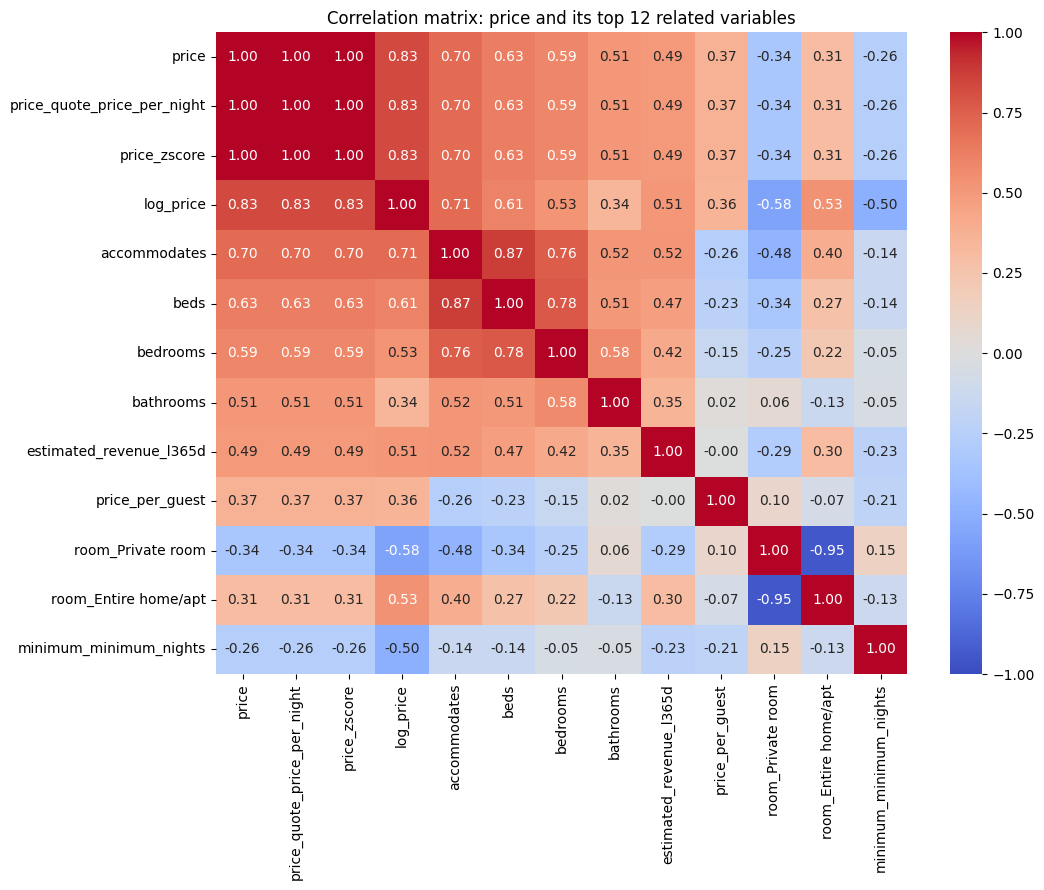

In [4]:
# Add code here 🔧
num_df = df.select_dtypes(include="number")
corr = num_df.corr()

price_corr = corr["price"].drop("price").sort_values(key=abs, ascending=False)
print(price_corr.head(15).round(3))

top_cols = ["price"] + price_corr.head(12).index.tolist()
plt.figure(figsize=(11, 9))
sns.heatmap(num_df[top_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix: price and its top 12 related variables")
plt.tight_layout()
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. Actual listing features that had the strongest correlations were accomodates, beds, bedrooms, and bathrooms. This makes sense, bigger listings that can accomdate more people will go for more money.

2. Accomodates and bathrooms might be the most useful predictors. Accomodates kind of tracks with beds and bedrooms so it really is the only needed one.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [5]:
# Add code here 🔧
df_model = df.dropna(subset=["price"]).copy()
print("Rows with a price:", len(df_model))

y = df_model["price"]

X = df_model.select_dtypes(include="number").drop(columns=["price"])
print("Predictors:", X.shape[1])

Rows with a price: 458
Predictors: 53


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. The predictors are all the numeric columns left. They fall into categories such as size/capacity, booking rules, availability, and location. These are features such as accomodates, bedrooms, beds, minimum nights, latitude and longitude.

2. This is a regression problem because the target is a continuous numerical value, and we want to predict an actual dollar amount. Classification will predict a category, that output would be a number, not a number. Regression also fits the business need, a host wants to know what to price their listing based on its attributes to be competitive within the market.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [6]:
# Add code here 🔧
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)

Training set: (366, 53)
Testing set:  (92, 53)


In [9]:
leaky = ["log_price", "price_zscore", "price_per_guest",
         "price_quote_total_price", "price_quote_price_per_night",
         "estimated_revenue_l365d"]
X_train = X_train.drop(columns=leaky, errors="ignore")
X_test  = X_test.drop(columns=leaky, errors="ignore")

train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test  = X_test.fillna(train_medians)

print("Predictors:", X_train.shape[1])
print("NaNs left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Predictors: 47
NaNs left: 0 0


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [10]:
# Add code here 🔧
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

pd.DataFrame({"Actual": y_test.values[:8], "Predicted": y_pred[:8].round(2)})

,Actual,Predicted
0,149.00,167.02
1,202.67,208.86
2,309.00,247.16
3,92.55,199.41
4,266.00,357.28
5,177.00,220.75
6,92.00,45.95
7,143.67,298.35


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [11]:
# Add code here 🔧
mse = mean_squared_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)

print(f"MSE: {mse:,.2f}")
print(f"RMSE: ${mse ** 0.5:,.2f}")
print(f"R²:  {r2:.3f}")

MSE: 10,661.78
RMSE: $103.26
R²:  0.528


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. R^2 is 0.528, so the model explain about 53% of the variation in nightly price on listings it hasn't seen, which is a moderate fit. The remaining 47% could possibly come from factors that the model doesn't account for such as photos or the age of amenities.

2. My MSE of 10,661 is large. It corresponds to a typical error of about 103 dollars on a median price of 146 dollars. To improve it, I could keep only the most impactful predictors to reduce overfitting, and model price logarithmically so a few expensive listings don't dominate.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [12]:
# Add code here 🔧
coef_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coef_table["Std_Coefficient"] = coef_table["Coefficient"] * X_train.std().values

coef_table = (coef_table
              .reindex(coef_table["Std_Coefficient"].abs().sort_values(ascending=False).index)
              .reset_index(drop=True))

coef_table.round(3)

,Feature,Coefficient,Std_Coefficient
0,minimum_nights_avg_ntm,-8.541,-95.661
1,accommodates,36.144,88.721
2,maximum_minimum_nights,4.810,59.713
3,calculated_host_listings_count_private_rooms,14.015,59.513
4,calculated_host_listings_count,-6.924,-54.127
5,number_of_reviews_ltm,1.782,36.060
6,calculated_host_listings_count_entire_homes,4.592,35.595
7,room_Entire home/apt,74.115,34.370
8,availability_eoy,0.514,29.355
9,estimated_occupancy_l365d,-0.319,-27.014


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Accomodates is the clearest driver, accounting for 36 dollars per additional guest. Next is entire room apt/house, at 74 extra dollars. Bathrooms was also significant at 43 dollars extra.

2. Yes, review scores checkin and review scores accuracy were both negative, which seems counterintuitive because better scores shouldn't lower price. Beds is also negative even though it correlates positively with price.

3. Price is driven mainly from property size and type. The capacity, number of batthrooms, and entire houses versus private rooms. Hosts can't change these things easily or really at all but this does help them value and price their lisitng based on the attributes they are working with.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [13]:
# Add code here 🔧
top_features = ["accommodates", "bathrooms", "minimum_nights_avg_ntm",
                "room_Entire home/apt", "review_scores_cleanliness"]

model_refined = LinearRegression()
model_refined.fit(X_train[top_features], y_train)
y_pred_refined = model_refined.predict(X_test[top_features])

comparison = pd.DataFrame({
    "Model": ["Baseline (47 features)", "Refined (5 features)"],
    "MSE": [mean_squared_error(y_test, y_pred), mean_squared_error(y_test, y_pred_refined)],
    "RMSE ($)": [mean_squared_error(y_test, y_pred) ** 0.5, mean_squared_error(y_test, y_pred_refined) ** 0.5],
    "R²": [r2_score(y_test, y_pred), r2_score(y_test, y_pred_refined)],
})
comparison.round(3)

,Model,MSE,RMSE ($),R²
0,Baseline (47 features),10661.775,103.256,0.528
1,Refined (5 features),8890.893,94.292,0.606


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept accomodates, bathrooms, minimun nights avg, room entire, and review scores cleanliness. They were among the among the strongest features in the coefficient table, and each one measures something different.

2. Yes. MSE fell to 8891, RMSE fell to 94, and r^2 rose to .606 on the test. The 47 feature model was overfitting and had many overlapping features. These five distinct features gave a more stable fit that generalizes better to new listings.

3. I would recommend the 5 feature model. It's not only more accurate on unseen listings, but it's also easier to explain. It also wouldn't be as rigorous to track all the features needed to use the model.

4. This assignment built skills I'll use in as an auditor. I applied professional skepticism by removing columns that leaked the answer and catching overlapping features before trusting the model. Predicting what a price should be and testing it on unseen data is also how analytical procedures work, where an auditor sets an expectation and investigates large differences.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The model helped answer what drives nightly price for Albany Airbnb listings. It also helped show how well price can be predicted from basic listing features.

2. I'd recommend hosts anchor their price on guest capacity, bathrooms, and whether the listing is an entire houst. Keep cleanliness high as that review metric is linked to higher prices. Airbnb could use the model as a price suggesting model and hosts could increase or decrease it from there as needed.

3. I could add neighborhood, amenities, and seasonality. I know Albany and surrounding areas get a more tourism traffic in the summer months. The summer time would command much higher rates than winter.

4. This relates to my audit goals because I questioned the data before trusting it, I removed leaky columns and overlapping features, which shows professional skepticism and awareness. Comparing predictions to reality and analyzing those gap is exactly how procedures work in audit.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"